In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import math

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")
if device.type == 'cuda':
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"VRAM: {torch.cuda.get_device_properties(0).total_memory / 1024**3:.1f} GB")

# ---- Hyperparameters (DeepSC replication baseline) ----
vocab_size      = 20000     # same as traditional
max_len         = 30        # DeepSC-aligned sequence length
pad_id          = 0

d_model         = 128       # DeepSC-aligned
nhead           = 8         # DeepSC replication baseline
num_enc_layers  = 4         # DeepSC replication baseline
num_dec_layers  = 4         # DeepSC replication baseline
dim_feedforward = 512       # DeepSC replication baseline
channel_dim     = 16        # DeepSC replication baseline
channel_hidden  = 256       # DeepSC replication baseline
channel_decoder_hidden = 512 # DeepSC replication baseline
dropout         = 0.1

print("\n--- DeepSC-Aligned Config ---")
print(f"d_model={d_model}, nhead={nhead}, enc_layers={num_enc_layers}, "
      f"dec_layers={num_dec_layers}, channel_dim={channel_dim}, ffn={dim_feedforward}, "
      f"channel_hidden={channel_hidden}, channel_decoder_hidden={channel_decoder_hidden}")

Using device: cuda
GPU: NVIDIA GeForce RTX 3050 Laptop GPU
VRAM: 4.0 GB

--- DeepSC-Aligned Config ---
d_model=128, nhead=8, enc_layers=4, dec_layers=4, channel_dim=16, ffn=512, channel_hidden=256, channel_decoder_hidden=512


In [2]:
# ---- Positional Encoding ----
# Injects position info so the transformer knows word ORDER
# Without this: "cat sat mat" == "mat sat cat" (same as traditional model's flaw)

class PositionalEncoding(nn.Module):
    """
    Standard sinusoidal positional encoding from 'Attention Is All You Need'.
    
    For each position pos and dimension i:
      PE(pos, 2i)   = sin(pos / 10000^(2i/d_model))
      PE(pos, 2i+1) = cos(pos / 10000^(2i/d_model))
    
    This gives each position a unique pattern the model can learn to use.
    """
    def __init__(self, d_model: int, max_len: int = 512, dropout: float = 0.1):
        super().__init__()
        self.dropout = nn.Dropout(p=dropout)

        # Create a matrix of shape (max_len, d_model)
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)  # (max_len, 1)
        div_term = torch.exp(
            torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model)
        )  # (d_model/2,)

        pe[:, 0::2] = torch.sin(position * div_term)   # even indices
        pe[:, 1::2] = torch.cos(position * div_term)   # odd indices

        pe = pe.unsqueeze(0)  # (1, max_len, d_model) — batch dim
        self.register_buffer('pe', pe)  # not a parameter, but saved with model

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        x: (batch, seq_len, d_model)
        adds positional encoding and applies dropout
        """
        x = x + self.pe[:, :x.size(1), :]
        return self.dropout(x)


# Sanity check
pe = PositionalEncoding(d_model=128, max_len=32)
dummy = torch.zeros(2, 32, 128)  # (batch=2, seq=32, dim=128)
out = pe(dummy)
print("Positional Encoding output shape:", out.shape)  # (2, 32, 128)
print("PE values at pos 0:", out[0, 0, :8].tolist())   # should be non-zero from sin/cos
print("PE values at pos 1:", out[0, 1, :8].tolist())   # different pattern from pos 0

Positional Encoding output shape: torch.Size([2, 32, 128])
PE values at pos 0: [0.0, 1.1111111640930176, 0.0, 1.1111111640930176, 0.0, 0.0, 0.0, 1.1111111640930176]
PE values at pos 1: [0.9349677562713623, 0.600335955619812, 0.8463560342788696, 0.7198954224586487, 0.7572904229164124, 0.0, 0.6718822717666626, 0.8849532604217529]


In [3]:
# ---- AWGN Channel ----
# Same noise model as traditional, but now applied to SEQUENCE of channel vectors
# not a single latent vector

def add_awgn(x: torch.Tensor, snr_db: float):
    """
    Add white Gaussian noise at a given SNR.
    
    x: (batch, seq_len, channel_dim)  — channel symbols to transmit
    
    Unlike traditional model where we had ONE latent vector per sentence,
    here we have a sequence of vectors — one per token position.
    Each position carries semantic info about that part of the sentence.
    """
    snr_linear = 10 ** (snr_db / 10)
    dims = tuple(range(1, x.dim()))
    signal_power = x.pow(2).mean(dim=dims, keepdim=True)
    noise_power = signal_power / snr_linear
    noise_std = noise_power.sqrt()
    noise = torch.randn_like(x) * noise_std
    return x + noise


# Sanity check
dummy_channel = torch.randn(2, 32, channel_dim)  # (batch=2, seq=32, channel_dim=16)
noisy = add_awgn(dummy_channel, snr_db=6.0)
print("AWGN check — input shape:", dummy_channel.shape, "output shape:", noisy.shape)
print("Mean abs noise at 6dB:", (noisy - dummy_channel).abs().mean().item())

AWGN check — input shape: torch.Size([2, 32, 16]) output shape: torch.Size([2, 32, 16])
Mean abs noise at 6dB: 0.3962564468383789


In [4]:
# ---- Channel Encoder & Channel Decoder ----
# These are the dense layers that sit BETWEEN the transformer and the channel.
#
# DeepSC architecture:
#   Semantic Encoder (Transformer) → Channel Encoder (Dense) → AWGN → Channel Decoder (Dense) → Semantic Decoder (Transformer)
#
# Channel Encoder: compress d_model (128) → channel_dim (16)  [8× compression]
# Channel Decoder: expand   channel_dim (16) → d_model (128)  [reconstruct]

class ChannelEncoder(nn.Module):
    """
    Compresses semantic features for transmission over the channel.
    
    Input:  (batch, seq_len, d_model)    — rich semantic vectors (128-dim)
    Output: (batch, seq_len, channel_dim) — compressed channel symbols (16-dim)
    
    Think of it as:
      Semantic encoder gives a detailed description of meaning.
      Channel encoder says "what's the minimum info I need to send?"
    """
    def __init__(self, d_model: int, channel_hidden: int, channel_dim: int):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(d_model, channel_hidden),       # 128 → 256
            nn.ReLU(),
            nn.Linear(channel_hidden, channel_dim),    # 256 → 16
        )
    
    def forward(self, x):
        return self.net(x)  # applied per token position independently


class ChannelDecoder(nn.Module):
    """
    Expands received (noisy) channel symbols back to semantic feature space.
    
    Input:  (batch, seq_len, channel_dim) — noisy received symbols (16-dim)
    Output: (batch, seq_len, d_model)     — reconstructed semantic vectors (128-dim)
    
    Think of it as:
      Channel decoder says "let me undo the compression and recover features
      so the semantic decoder can understand the meaning."
    """
    def __init__(self, channel_dim: int, d_model: int, channel_decoder_hidden: int):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(channel_dim, channel_decoder_hidden),    # 16 → 512
            nn.ReLU(),
            nn.Linear(channel_decoder_hidden, d_model),        # 512 → 128
        )
    
    def forward(self, x):
        return self.net(x)


# Sanity check
ch_enc = ChannelEncoder(d_model=d_model, channel_hidden=channel_hidden, channel_dim=channel_dim)
ch_dec = ChannelDecoder(channel_dim=channel_dim, d_model=d_model, channel_decoder_hidden=channel_decoder_hidden)

dummy_semantic = torch.randn(2, 32, 128)          # (batch, seq, d_model)
compressed = ch_enc(dummy_semantic)                 # (batch, seq, channel_dim)
noisy_compressed = add_awgn(compressed, snr_db=6.0) # add channel noise
recovered = ch_dec(noisy_compressed)                # (batch, seq, d_model)

print(f"Semantic features: {dummy_semantic.shape}")
print(f"After channel enc: {compressed.shape}")
print(f"After AWGN noise:  {noisy_compressed.shape}")
print(f"After channel dec: {recovered.shape}")

Semantic features: torch.Size([2, 32, 128])
After channel enc: torch.Size([2, 32, 16])
After AWGN noise:  torch.Size([2, 32, 16])
After channel dec: torch.Size([2, 32, 128])


In [5]:
# ---- Full DeepSC Model (v4 — with beam search generate) ----
#
# Complete pipeline:
#   tokens → embedding + PE → Transformer Encoder (semantic)
#         → Channel Encoder → AWGN → Channel Decoder
#         → Transformer Decoder (semantic) → vocab logits
#
# v4 additions:
#   - beam_search() for higher-quality decoding
#   - generate() kept for greedy baseline

class DeepSCModel(nn.Module):
    def __init__(self, vocab_size, d_model, nhead, num_enc_layers, num_dec_layers,
                 dim_feedforward, channel_dim, channel_hidden, channel_decoder_hidden, max_len, pad_id, dropout=0.1):
        super().__init__()
        self.d_model = d_model
        self.pad_id = pad_id
        self.max_len = max_len

        # ---- Shared Embedding + Positional Encoding ----
        self.embedding = nn.Embedding(vocab_size, d_model, padding_idx=pad_id)
        self.pos_encoder = PositionalEncoding(d_model, max_len, dropout)

        # ---- Semantic Encoder (Transformer) ----
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            batch_first=True,
        )
        self.semantic_encoder = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_enc_layers,
        )

        # ---- Channel Encoder / Decoder ----
        self.channel_encoder = ChannelEncoder(d_model, channel_hidden, channel_dim)
        self.channel_decoder = ChannelDecoder(channel_dim, d_model, channel_decoder_hidden)

        # ---- Semantic Decoder (Transformer) ----
        decoder_layer = nn.TransformerDecoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            batch_first=True,
        )
        self.semantic_decoder = nn.TransformerDecoder(
            decoder_layer,
            num_layers=num_dec_layers,
        )

        # ---- Output projection ----
        self.output_layer = nn.Linear(d_model, vocab_size)

    def _generate_causal_mask(self, sz: int, device: torch.device):
        mask = torch.triu(torch.ones(sz, sz, device=device), diagonal=1).bool()
        return mask

    def _encode_and_transmit(self, input_ids, attention_mask, snr_db):
        """Shared encoder + channel path for both greedy and beam search."""
        emb = self.embedding(input_ids) * math.sqrt(self.d_model)
        emb = self.pos_encoder(emb)
        src_key_padding_mask = (attention_mask == 0)
        semantic_features = self.semantic_encoder(emb, src_key_padding_mask=src_key_padding_mask)
        channel_symbols = self.channel_encoder(semantic_features)
        received_symbols = add_awgn(channel_symbols, snr_db)
        memory = self.channel_decoder(received_symbols)
        return memory, src_key_padding_mask

    def _decode_step(self, generated, memory, src_key_padding_mask):
        """Run decoder on current sequence, return logits for last position."""
        dec_emb = self.embedding(generated) * math.sqrt(self.d_model)
        dec_emb = self.pos_encoder(dec_emb)
        causal_mask = self._generate_causal_mask(generated.size(1), generated.device)
        dec_out = self.semantic_decoder(
            dec_emb, memory,
            tgt_mask=causal_mask,
            memory_key_padding_mask=src_key_padding_mask,
        )
        return self.output_layer(dec_out[:, -1, :])  # (B, vocab_size)

    def forward(self, input_ids, attention_mask, snr_db=6.0, return_intermediates=False):
        B, L = input_ids.shape

        # ---- Encoder side ----
        emb = self.embedding(input_ids) * math.sqrt(self.d_model)
        emb = self.pos_encoder(emb)
        src_key_padding_mask = (attention_mask == 0)

        semantic_features = self.semantic_encoder(
            emb, src_key_padding_mask=src_key_padding_mask,
        )

        # ---- Channel ----
        channel_symbols = self.channel_encoder(semantic_features)
        received_symbols = add_awgn(channel_symbols, snr_db)
        decoded_features = self.channel_decoder(received_symbols)

        # ---- Decoder side (teacher forced) ----
        dec_emb = self.embedding(input_ids) * math.sqrt(self.d_model)
        dec_emb = self.pos_encoder(dec_emb)
        causal_mask = self._generate_causal_mask(L, input_ids.device)

        dec_output = self.semantic_decoder(
            dec_emb, decoded_features,
            tgt_mask=causal_mask,
            tgt_key_padding_mask=src_key_padding_mask,
            memory_key_padding_mask=src_key_padding_mask,
        )

        logits = self.output_layer(dec_output)

        if return_intermediates:
            return logits, semantic_features, dec_output
        return logits

    @torch.no_grad()
    def generate(self, input_ids, attention_mask, snr_db=6.0,
                 sos_id=1, eos_id=2, max_len=None):
        """Greedy autoregressive decoding (baseline)."""
        self.eval()
        max_len = self.max_len if max_len is None else max_len
        B = input_ids.size(0)
        memory, src_pad = self._encode_and_transmit(input_ids, attention_mask, snr_db)

        generated = torch.full((B, 1), sos_id, dtype=torch.long, device=input_ids.device)
        for step in range(max_len - 1):
            next_logits = self._decode_step(generated, memory, src_pad)
            next_token = next_logits.argmax(dim=-1, keepdim=True)
            generated = torch.cat([generated, next_token], dim=1)
            if (next_token == eos_id).all():
                break
        return generated

    @torch.no_grad()
    def beam_search(self, input_ids, attention_mask, snr_db=6.0,
                    sos_id=1, eos_id=2, max_len=None,
                    beam_width=5, length_penalty=0.6):
        """
        Beam search decoding — explores top-k hypotheses at each step.
        Processes one sample at a time (input_ids should be (1, L)).
        Returns best hypothesis as (1, seq_len) tensor.
        """
        self.eval()
        max_len = self.max_len if max_len is None else max_len
        assert input_ids.size(0) == 1, "beam_search expects batch_size=1"
        device = input_ids.device

        memory, src_pad = self._encode_and_transmit(input_ids, attention_mask, snr_db)

        # Each beam: (log_prob, token_sequence)
        # Start with <SOS>
        beams = [(0.0, [sos_id])]
        completed = []

        for step in range(max_len - 1):
            all_candidates = []

            for score, seq in beams:
                if seq[-1] == eos_id:
                    completed.append((score, seq))
                    continue

                # Decode
                gen_tensor = torch.tensor([seq], dtype=torch.long, device=device)
                logits = self._decode_step(gen_tensor, memory, src_pad)
                log_probs = F.log_softmax(logits[0], dim=-1)

                # Top-k expansions
                topk_log_probs, topk_ids = log_probs.topk(beam_width)
                for i in range(beam_width):
                    new_score = score + topk_log_probs[i].item()
                    new_seq = seq + [topk_ids[i].item()]
                    all_candidates.append((new_score, new_seq))

            if not all_candidates:
                break

            # Length-normalized scoring: score / len^alpha
            def norm_score(candidate):
                s, seq = candidate
                return s / (len(seq) ** length_penalty)

            all_candidates.sort(key=norm_score, reverse=True)
            beams = all_candidates[:beam_width]

            # Early stop if all beams ended
            if all(seq[-1] == eos_id for _, seq in beams):
                completed.extend(beams)
                break

        # Add any remaining beams
        completed.extend(beams)

        # Pick best by normalized score
        def norm_score_final(candidate):
            s, seq = candidate
            return s / (len(seq) ** length_penalty)

        best_score, best_seq = max(completed, key=norm_score_final)
        return torch.tensor([best_seq], dtype=torch.long, device=device)


# ---- Instantiate ----
model = DeepSCModel(
    vocab_size=vocab_size,
    d_model=d_model,
    nhead=nhead,
    num_enc_layers=num_enc_layers,
    num_dec_layers=num_dec_layers,
    dim_feedforward=dim_feedforward,
    channel_dim=channel_dim,
    channel_hidden=channel_hidden,
    channel_decoder_hidden=channel_decoder_hidden,
    max_len=max_len,
    pad_id=pad_id,
    dropout=dropout,
).to(device)

# v4: training from scratch — do NOT load old checkpoint (different dimensions)
print("v4 model initialized from scratch (new architecture)")

total_params = sum(p.numel() for p in model.parameters())
print(f"Total parameters: {total_params:,}")

# Sanity check both decoding methods
fake_ids = torch.randint(1, vocab_size, (1, max_len), device=device)
fake_mask = torch.ones(1, max_len, dtype=torch.long, device=device)
with torch.no_grad():
    greedy_out = model.generate(fake_ids, fake_mask, snr_db=6.0, sos_id=1, eos_id=2)
    beam_out = model.beam_search(fake_ids, fake_mask, snr_db=6.0, sos_id=1, eos_id=2, beam_width=5)
print(f"Greedy output shape: {greedy_out.shape}")
print(f"Beam search output shape: {beam_out.shape}")
print("Beam search ready (width=5, length_penalty=0.6)")

v4 model initialized from scratch (new architecture)
Total parameters: 7,102,896


d:\btp_reso\btp_env\Lib\site-packages\torch\nn\modules\transformer.py:502: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\builder\windows\pytorch\aten\src\ATen\NestedTensorImpl.cpp:180.)
  output = torch._nested_tensor_from_mask(


Greedy output shape: torch.Size([1, 30])
Beam search output shape: torch.Size([1, 30])
Beam search ready (width=5, length_penalty=0.6)


In [6]:
# ---- Load Data (Europarl local corpus, batch_size=32 for v4 model VRAM fit) ----
from pathlib import Path
from data_prep import load_and_prepare, get_dataloaders, PAD, SOS, EOS, UNK

# Prefer europarl/text; fallback to europarl if layout differs.
europarl_candidates = [Path("europarl/text"), Path("europarl")]
europarl_dir = next((p for p in europarl_candidates if p.exists() and p.is_dir()), None)
if europarl_dir is None:
    raise FileNotFoundError(
        "Europarl directory not found. Expected one of: europarl/text or europarl"
    )

text_files = sorted(europarl_dir.glob("*.txt")) + sorted(europarl_dir.glob("*.en"))
if not text_files and europarl_dir.name == "europarl" and (europarl_dir / "text").exists():
    europarl_dir = europarl_dir / "text"
    text_files = sorted(europarl_dir.glob("*.txt")) + sorted(europarl_dir.glob("*.en"))

if not text_files:
    raise FileNotFoundError(f"No .txt/.en files found in: {europarl_dir.resolve()}")

dataset_encoded, vocab, stoi, itos, pad_id = load_and_prepare(
    max_len=max_len,
    max_vocab_size=vocab_size,
    min_freq=1,
    seed=42,
    dataset_name='europarl',
    split_protocol='90_10_train_test',
    europarl_min_words=4,
    europarl_max_words=30,
    europarl_local_dir=str(europarl_dir),
)

loaders = get_dataloaders(dataset_encoded, pad_id=pad_id, batch_size=128)

print("Europarl dir:", europarl_dir.resolve())
print("Europarl files:", len(text_files))
print({split: len(dataset_encoded[split]) for split in dataset_encoded})
print("Vocab size:", len(vocab))

batch = next(iter(loaders['train']))
print(f"Batch shapes: {batch['input_ids'].shape}, {batch['attention_mask'].shape}")

Filter:   0%|          | 0/1574113 [00:00<?, ? examples/s]

Map:   0%|          | 0/106348 [00:00<?, ? examples/s]

Map:   0%|          | 0/11817 [00:00<?, ? examples/s]

Map:   0%|          | 0/11817 [00:00<?, ? examples/s]

Europarl dir: D:\btp_reso\btp_env\europarl\text
Europarl files: 9672
{'train': 106348, 'validation': 11817, 'test': 11817}
Vocab size: 20000
Batch shapes: torch.Size([128, 30]), torch.Size([128, 30])


In [7]:
# ---- v4: SBERT-Guided Training + Resume Checkpoint (.pkl) ----
# Keeps your current setup, but adds robust resume from semantic_checkpoint.pkl

import random
import pickle
from pathlib import Path
from sentence_transformers import SentenceTransformer

# ---- Load SBERT as frozen teacher ----
sbert_teacher = SentenceTransformer('all-MiniLM-L6-v2', device=str(device))
sbert_teacher.eval()
for p in sbert_teacher.parameters():
    p.requires_grad = False
print(f"SBERT loaded: {sum(p.numel() for p in sbert_teacher.parameters()):,} params (frozen)")

# ---- Projection head: DeepSC decoder space (d_model) -> SBERT space (384) ----
sbert_projection = nn.Sequential(
    nn.Linear(d_model, 384),
    nn.ReLU(),
    nn.Linear(384, 384),
).to(device)
print(f"Projection head: {sum(p.numel() for p in sbert_projection.parameters()):,} params")

# ---- Training setup ----
criterion = nn.CrossEntropyLoss(ignore_index=pad_id, label_smoothing=0.0)
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-4,
    betas=(0.9, 0.98),
    eps=1e-8,
    weight_decay=5e-4,
)
sbert_weight = 0.0

# ---- Constant LR implemented via LambdaLR ----
num_epochs_v4 = 80
warmup_epochs = 0

def lr_lambda(epoch):
    return 1.0

scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)

# ---- Resume checkpoint state ----
checkpoint_path = Path("semantic_checkpoint.pkl")
start_epoch = 1
best_val = float('inf')
history_v4 = {'train_loss': [], 'val_loss': [], 'ce_loss': [], 'sbert_loss': [], 'lr': []}

if checkpoint_path.exists():
    with checkpoint_path.open('rb') as f:
        checkpoint = pickle.load(f)

    model.load_state_dict(checkpoint['model_state'])
    if 'sbert_projection_state' in checkpoint:
        sbert_projection.load_state_dict(checkpoint['sbert_projection_state'])
    if 'optimizer_state' in checkpoint:
        optimizer.load_state_dict(checkpoint['optimizer_state'])
    if 'scheduler_state' in checkpoint:
        scheduler.load_state_dict(checkpoint['scheduler_state'])

    best_val = checkpoint.get('best_val', best_val)
    history_v4 = checkpoint.get('history_v4', history_v4)
    start_epoch = int(checkpoint.get('epoch', 0)) + 1

    print(f"Loaded checkpoint from {checkpoint_path}")
    print(f"  Resume from epoch {start_epoch}/{num_epochs_v4}")
    print(f"  Best val so far: {best_val:.4f}")
else:
    print("No checkpoint found, starting v4 training from scratch.")

# Helper: convert token IDs to text strings for SBERT
eos_id_val = stoi[EOS]
special_set = {pad_id, stoi[SOS], stoi[EOS], stoi[UNK]}

def ids_to_texts(id_tensor):
    texts = []
    for ids in id_tensor:
        toks = []
        for i in ids.tolist():
            if i == eos_id_val:
                break
            if i in special_set:
                continue
            toks.append(itos.get(i, '<UNK>'))
        texts.append(' '.join(toks) if toks else 'the')
    return texts


def train_one_epoch_v4(model, sbert_teacher, sbert_projection, loader, optimizer,
                       criterion, sbert_weight=0.0, max_grad_norm=1.0):
    model.train()
    sbert_projection.train()
    total_loss = 0.0
    total_ce = 0.0
    total_sbert = 0.0

    for batch in loader:
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)

        snr_db = random.uniform(5, 10)

        optimizer.zero_grad()
        logits, enc_features, dec_features = model(
            input_ids, attention_mask, snr_db=snr_db, return_intermediates=True
        )

        ce_loss = criterion(
            logits[:, :-1].contiguous().view(-1, vocab_size),
            input_ids[:, 1:].contiguous().view(-1),
        )

        with torch.no_grad():
            texts = ids_to_texts(input_ids.cpu())
            sbert_ref = sbert_teacher.encode(texts, convert_to_tensor=True, device=device)

        mask_f = attention_mask.unsqueeze(-1).float()
        dec_pooled = (dec_features * mask_f).sum(dim=1) / mask_f.sum(dim=1).clamp(min=1)
        dec_projected = sbert_projection(dec_pooled)

        cos_sim = F.cosine_similarity(dec_projected, sbert_ref, dim=-1).mean()
        sbert_loss = 1.0 - cos_sim

        loss = ce_loss + sbert_weight * sbert_loss
        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            list(model.parameters()) + list(sbert_projection.parameters()),
            max_norm=max_grad_norm,
        )
        optimizer.step()

        bs = input_ids.size(0)
        total_loss += loss.item() * bs
        total_ce += ce_loss.item() * bs
        total_sbert += sbert_loss.item() * bs

    n = len(loader.dataset)
    return total_loss / n, total_ce / n, total_sbert / n


def evaluate_loss_v4(model, loader, criterion, snr_db):
    model.eval()
    total_loss = 0.0
    with torch.no_grad():
        for batch in loader:
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            logits = model(input_ids, attention_mask, snr_db=snr_db)
            loss = criterion(
                logits[:, :-1].contiguous().view(-1, vocab_size),
                input_ids[:, 1:].contiguous().view(-1),
            )
            total_loss += loss.item() * input_ids.size(0)
    return total_loss / len(loader.dataset)

print("v4 training functions ready.")
print(f"  - d_model={d_model}, channel_dim={channel_dim}, layers={num_enc_layers}")
print(f"  - Label smoothing: 0.0")
print(f"  - Adam lr=1e-4, betas=(0.9,0.98), eps=1e-8, weight_decay=5e-4")
print(f"  - Constant LR, {num_epochs_v4} total epochs")
print(f"  - SBERT loss weight: {sbert_weight}")
print(f"  - Checkpoint path: {checkpoint_path}")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


SBERT loaded: 22,713,216 params (frozen)
Projection head: 197,376 params
Loaded checkpoint from semantic_checkpoint.pkl
  Resume from epoch 81/80
  Best val so far: 1.8604
v4 training functions ready.
  - d_model=128, channel_dim=16, layers=4
  - Label smoothing: 0.0
  - Adam lr=1e-4, betas=(0.9,0.98), eps=1e-8, weight_decay=5e-4
  - Constant LR, 80 total epochs
  - SBERT loss weight: 0.0
  - Checkpoint path: semantic_checkpoint.pkl


In [8]:
# ---- v4 Training Loop (with resume support) ----
# Resumes from semantic_checkpoint.pkl if available

if start_epoch > num_epochs_v4:
    print(f"Training already completed up to epoch {start_epoch - 1}. Nothing to run.")
else:
    for epoch in range(start_epoch, num_epochs_v4 + 1):
        train_loss, ce_loss, sbert_loss = train_one_epoch_v4(
            model, sbert_teacher, sbert_projection, loaders['train'],
            optimizer, criterion, sbert_weight=sbert_weight,
        )
        val_loss = evaluate_loss_v4(model, loaders['validation'], criterion, snr_db=6.0)
        current_lr = optimizer.param_groups[0]['lr']
        scheduler.step()

        history_v4['train_loss'].append(train_loss)
        history_v4['val_loss'].append(val_loss)
        history_v4['ce_loss'].append(ce_loss)
        history_v4['sbert_loss'].append(sbert_loss)
        history_v4['lr'].append(current_lr)

        print(f"Epoch {epoch}/{num_epochs_v4}: "
              f"total={train_loss:.4f}  CE={ce_loss:.4f}  SBERT={sbert_loss:.4f}  "
              f"val={val_loss:.4f}  lr={current_lr:.2e}")

        if val_loss < best_val:
            best_val = val_loss
            torch.save(model.state_dict(), 'semantic_best.pt')
            print(f"  -> Saved best model (val={best_val:.4f})")

        # Save full training state each epoch for resume
        checkpoint = {
            'epoch': epoch,
            'model_state': model.state_dict(),
            'sbert_projection_state': sbert_projection.state_dict(),
            'optimizer_state': optimizer.state_dict(),
            'scheduler_state': scheduler.state_dict(),
            'best_val': best_val,
            'history_v4': history_v4,
        }
        with checkpoint_path.open('wb') as f:
            pickle.dump(checkpoint, f)
        print(f"  -> Checkpoint updated: {checkpoint_path}")

print(f"\nBest validation loss: {best_val:.4f}")

Epoch 1/80: total=6.5085  CE=6.5085  SBERT=1.0088  val=5.4333  lr=1.00e-04
  -> Saved best model (val=5.4333)
  -> Checkpoint updated: semantic_checkpoint.pkl
Epoch 2/80: total=5.2030  CE=5.2030  SBERT=1.0058  val=4.8623  lr=1.00e-04
  -> Saved best model (val=4.8623)
  -> Checkpoint updated: semantic_checkpoint.pkl
Epoch 3/80: total=4.7883  CE=4.7883  SBERT=1.0061  val=4.5418  lr=1.00e-04
  -> Saved best model (val=4.5418)
  -> Checkpoint updated: semantic_checkpoint.pkl
Epoch 4/80: total=4.5317  CE=4.5317  SBERT=1.0063  val=4.3324  lr=1.00e-04
  -> Saved best model (val=4.3324)
  -> Checkpoint updated: semantic_checkpoint.pkl
Epoch 5/80: total=4.3625  CE=4.3625  SBERT=1.0061  val=4.1840  lr=1.00e-04
  -> Saved best model (val=4.1840)
  -> Checkpoint updated: semantic_checkpoint.pkl
Epoch 6/80: total=4.2390  CE=4.2390  SBERT=1.0065  val=4.0763  lr=1.00e-04
  -> Saved best model (val=4.0763)
  -> Checkpoint updated: semantic_checkpoint.pkl
Epoch 7/80: total=4.1378  CE=4.1378  SBERT=1.0

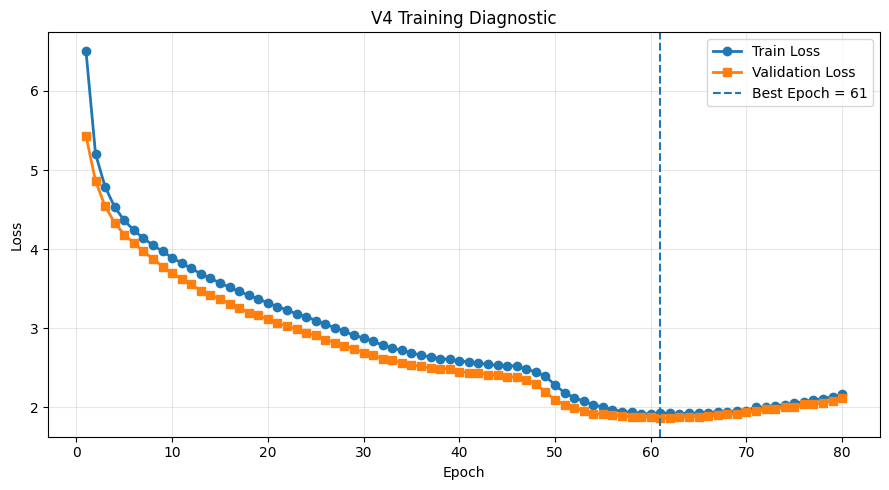

Best val loss: 1.8604 at epoch 61
Epochs since last improvement: 19
Recommendation: STOP v4 (no improvement for 19 epochs).
Use [semantic_best.pt](http://_vscodecontentref_/2) for evaluation / v5 fine-tuning.


In [8]:
import numpy as np
import matplotlib.pyplot as plt

# ---- Training diagnostic plot: do we still need more epochs? ----
patience = 8  # how many epochs without val improvement before saying "stop"

train = np.array(history_v4["train_loss"], dtype=float)
val = np.array(history_v4["val_loss"], dtype=float)

if len(val) == 0:
    print("No training history found yet.")
else:
    epochs = np.arange(1, len(val) + 1)
    best_epoch = int(np.argmin(val) + 1)
    best_val = float(np.min(val))

    # last epoch where a new best was achieved
    best_so_far = np.minimum.accumulate(val)
    improved = np.r_[True, np.diff(best_so_far) < 0]
    last_improve_epoch = int(np.where(improved)[0][-1] + 1)
    no_improve_epochs = int(len(val) - last_improve_epoch)

    plt.figure(figsize=(9, 5))
    plt.plot(epochs, train, marker="o", linewidth=2, label="Train Loss")
    plt.plot(epochs, val, marker="s", linewidth=2, label="Validation Loss")
    plt.axvline(best_epoch, linestyle="--", linewidth=1.5, label=f"Best Epoch = {best_epoch}")
    plt.title("V4 Training Diagnostic")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

    print(f"Best val loss: {best_val:.4f} at epoch {best_epoch}")
    print(f"Epochs since last improvement: {no_improve_epochs}")

    if no_improve_epochs >= patience:
        print(f"Recommendation: STOP v4 (no improvement for {no_improve_epochs} epochs).")
        print("Use [semantic_best.pt](http://_vscodecontentref_/2) for evaluation / v5 fine-tuning.")
    else:
        print("Recommendation: You can continue a few more epochs and re-check.")

In [9]:
from nltk.translate.bleu_score import sentence_bleu

special_ids = {pad_id, stoi[SOS], stoi[EOS], stoi[UNK]}

def decode_tokens(id_list):
    toks = []
    for i in id_list:
        if i == stoi[EOS]:
            break
        if i in special_ids:
            continue
        toks.append(itos.get(i, UNK))
    return ' '.join(toks)


def eval_bleu_all(model, loader, snr_db: float, max_batches: int = 50):
    model.eval()
    scores_1, scores_2, scores_3, scores_4 = [], [], [], []
    sos_id = stoi[SOS]
    eos_id = stoi[EOS]
    seen_batches = 0

    with torch.no_grad():
        for batch in loader:
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            bsz = input_ids.size(0)

            for i in range(bsz):
                inp = input_ids[i:i+1]
                msk = attention_mask[i:i+1]

                ref = decode_tokens(input_ids[i].cpu().tolist())
                ref_tokens = ref.split()
                if not ref_tokens:
                    continue

                pred_ids = model.generate(inp, msk, snr_db=snr_db, sos_id=sos_id, eos_id=eos_id, max_len=max_len)
                hyp = decode_tokens(pred_ids.cpu().squeeze(0).tolist())
                hyp_tokens = hyp.split() if hyp.split() else ['the']

                scores_1.append(sentence_bleu([ref_tokens], hyp_tokens, weights=(1, 0, 0, 0), smoothing_function=None))
                scores_2.append(sentence_bleu([ref_tokens], hyp_tokens, weights=(0.5, 0.5, 0, 0), smoothing_function=None))
                scores_3.append(sentence_bleu([ref_tokens], hyp_tokens, weights=(1/3, 1/3, 1/3, 0), smoothing_function=None))
                scores_4.append(sentence_bleu([ref_tokens], hyp_tokens, weights=(0.25, 0.25, 0.25, 0.25), smoothing_function=None))

            seen_batches += 1
            if seen_batches >= max_batches:
                break

    return {
        'bleu1': sum(scores_1) / len(scores_1) if scores_1 else 0.0,
        'bleu2': sum(scores_2) / len(scores_2) if scores_2 else 0.0,
        'bleu3': sum(scores_3) / len(scores_3) if scores_3 else 0.0,
        'bleu4': sum(scores_4) / len(scores_4) if scores_4 else 0.0,
    }


d:\btp_reso\btp_env\Lib\site-packages\nltk\translate\bleu_score.py:577: UserWarning: 
The hypothesis contains 0 counts of 3-gram overlaps.
Therefore the BLEU score evaluates to 0, independently of
how many N-gram overlaps of lower order it contains.
Consider using lower n-gram order or use SmoothingFunction()
  warnings.warn(_msg)
d:\btp_reso\btp_env\Lib\site-packages\nltk\translate\bleu_score.py:577: UserWarning: 
The hypothesis contains 0 counts of 4-gram overlaps.
Therefore the BLEU score evaluates to 0, independently of
how many N-gram overlaps of lower order it contains.
Consider using lower n-gram order or use SmoothingFunction()
  warnings.warn(_msg)
d:\btp_reso\btp_env\Lib\site-packages\nltk\translate\bleu_score.py:577: UserWarning: 
The hypothesis contains 0 counts of 2-gram overlaps.
Therefore the BLEU score evaluates to 0, independently of
how many N-gram overlaps of lower order it contains.
Consider using lower n-gram order or use SmoothingFunction()
  warnings.warn(_msg)


SNR   0 dB | BLEU1=0.4722 BLEU2=0.3266 BLEU3=0.2454 BLEU4=0.2004
SNR   3 dB | BLEU1=0.6202 BLEU2=0.4936 BLEU3=0.4025 BLEU4=0.3364
SNR   6 dB | BLEU1=0.7321 BLEU2=0.6308 BLEU3=0.5497 BLEU4=0.4753
SNR   9 dB | BLEU1=0.7896 BLEU2=0.7056 BLEU3=0.6344 BLEU4=0.5652
SNR  12 dB | BLEU1=0.8121 BLEU2=0.7362 BLEU3=0.6702 BLEU4=0.6033
SNR  15 dB | BLEU1=0.8207 BLEU2=0.7484 BLEU3=0.6846 BLEU4=0.6201
SNR  18 dB | BLEU1=0.8256 BLEU2=0.7545 BLEU3=0.6916 BLEU4=0.6278
Saved: semantic_results_v4_latest.csv


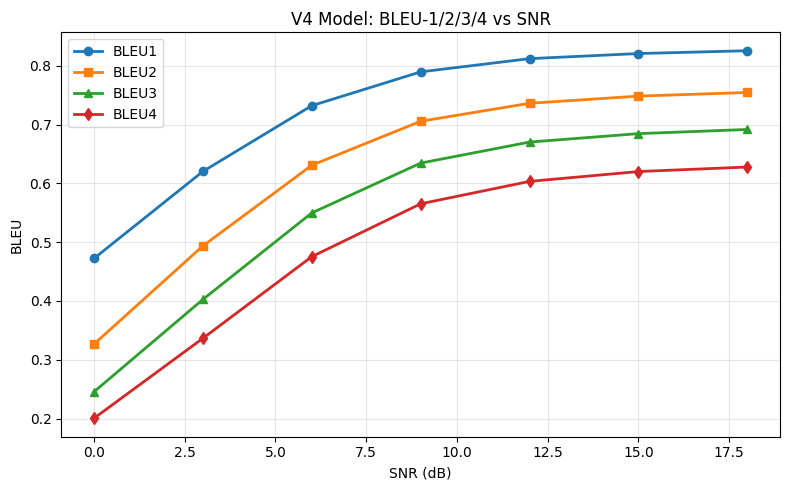

Saved: semantic_v4_bleu1234_snr.png


In [10]:
import torch
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ---- BLEU-1/2/3/4 vs SNR for v4 ----
# Requires: model, loaders, eval_bleu_all() already defined
ckpt_v4 = Path("semantic_best.pt")
if not ckpt_v4.exists():
    raise FileNotFoundError(f"Missing checkpoint: {ckpt_v4}")

model.load_state_dict(torch.load(ckpt_v4, map_location=device, weights_only=True))
model.to(device)
model.eval()

snr_values = [0, 3, 6, 9, 12, 15, 18]
max_batches = len(loaders["test"])  # full test split

rows = []
for snr in snr_values:
    scores = eval_bleu_all(model, loaders["test"], snr_db=snr, max_batches=max_batches)
    rows.append({"snr_db": snr, **scores})
    print(
        f"SNR {snr:>3} dB | "
        f"BLEU1={scores['bleu1']:.4f} "
        f"BLEU2={scores['bleu2']:.4f} "
        f"BLEU3={scores['bleu3']:.4f} "
        f"BLEU4={scores['bleu4']:.4f}"
    )

df_v4 = pd.DataFrame(rows)
csv_out = Path("semantic_results_v4_latest.csv")
df_v4.to_csv(csv_out, index=False)
print(f"Saved: {csv_out}")

# Plot
plt.figure(figsize=(8, 5))
for col, marker in [("bleu1", "o"), ("bleu2", "s"), ("bleu3", "^"), ("bleu4", "d")]:
    if col in df_v4.columns:
        plt.plot(df_v4["snr_db"], df_v4[col], marker=marker, linewidth=2, label=col.upper())

plt.xlabel("SNR (dB)")
plt.ylabel("BLEU")
plt.title("V4 Model: BLEU-1/2/3/4 vs SNR")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

fig_out = Path("semantic_v4_bleu1234_snr.png")
plt.savefig(fig_out, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {fig_out}")

d:\btp_reso\btp_env\Lib\site-packages\nltk\translate\bleu_score.py:577: UserWarning: 
The hypothesis contains 0 counts of 4-gram overlaps.
Therefore the BLEU score evaluates to 0, independently of
how many N-gram overlaps of lower order it contains.
Consider using lower n-gram order or use SmoothingFunction()
  warnings.warn(_msg)
d:\btp_reso\btp_env\Lib\site-packages\nltk\translate\bleu_score.py:577: UserWarning: 
The hypothesis contains 0 counts of 2-gram overlaps.
Therefore the BLEU score evaluates to 0, independently of
how many N-gram overlaps of lower order it contains.
Consider using lower n-gram order or use SmoothingFunction()
  warnings.warn(_msg)
d:\btp_reso\btp_env\Lib\site-packages\nltk\translate\bleu_score.py:577: UserWarning: 
The hypothesis contains 0 counts of 3-gram overlaps.
Therefore the BLEU score evaluates to 0, independently of
how many N-gram overlaps of lower order it contains.
Consider using lower n-gram order or use SmoothingFunction()
  warnings.warn(_msg)


Collected 11816 per-sentence BLEU scores at SNR 6.0 dB


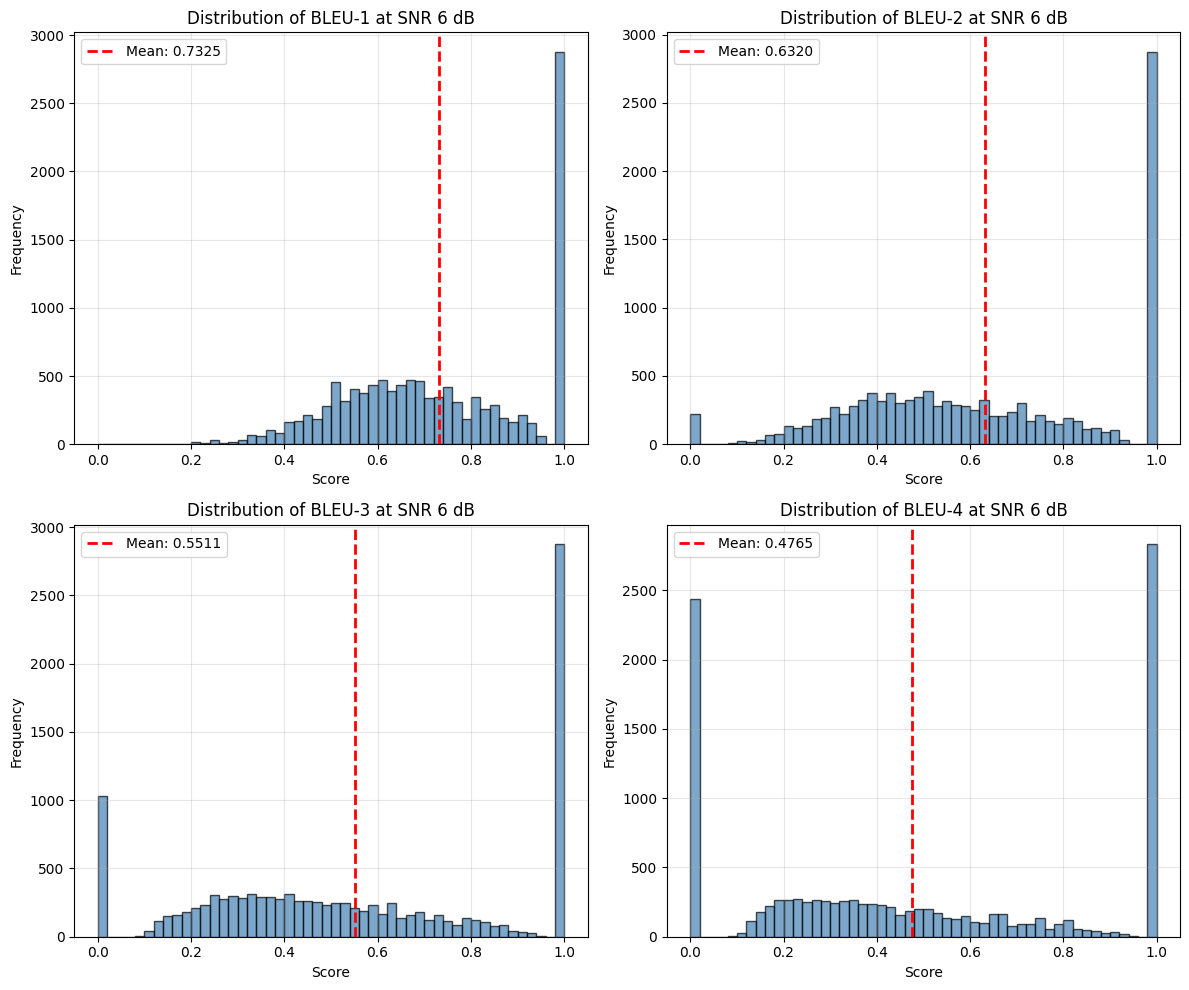


BLEU Score Statistics at SNR 6.0 dB:
BLEU1 — Mean: 0.7325, Std: 0.2012, Min: 0.0000, Max: 1.0000
BLEU2 — Mean: 0.6320, Std: 0.2723, Min: 0.0000, Max: 1.0000
BLEU3 — Mean: 0.5511, Std: 0.3277, Min: 0.0000, Max: 1.0000
BLEU4 — Mean: 0.4765, Std: 0.3688, Min: 0.0000, Max: 1.0000

Saved: semantic_v4_bleu1234_distribution_snr6.png


In [19]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from nltk.translate.bleu_score import sentence_bleu

# ---- Distribution of BLEU-1/2/3/4 scores at SNR 6 dB for semantic v4 ----

ckpt_v4 = Path("semantic_best.pt")
if not ckpt_v4.exists():
    raise FileNotFoundError(f"Missing checkpoint: {ckpt_v4}")

model.load_state_dict(torch.load(ckpt_v4, map_location=device, weights_only=True))
model.to(device)
model.eval()

snr_db = 6.0
max_batches = len(loaders["test"])

# Collect per-sentence BLEU scores (not averaged)
bleu1_scores = []
bleu2_scores = []
bleu3_scores = []
bleu4_scores = []

sos_id = stoi[SOS]
eos_id = stoi[EOS]
special_ids = {pad_id, stoi[SOS], stoi[EOS], stoi[UNK]}

def decode_tokens(id_list):
    toks = []
    for i in id_list:
        if i == stoi[EOS]:
            break
        if i in special_ids:
            continue
        toks.append(itos.get(i, UNK))
    return ' '.join(toks)

with torch.no_grad():
    for batch_idx, batch in enumerate(loaders["test"]):
        if batch_idx >= max_batches:
            break
        
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        bsz = input_ids.size(0)

        for i in range(bsz):
            inp = input_ids[i:i+1]
            msk = attention_mask[i:i+1]

            ref = decode_tokens(input_ids[i].cpu().tolist())
            ref_tokens = ref.split()
            if not ref_tokens:
                continue

            pred_ids = model.generate(inp, msk, snr_db=snr_db, sos_id=sos_id, eos_id=eos_id, max_len=max_len)
            hyp = decode_tokens(pred_ids.cpu().squeeze(0).tolist())
            hyp_tokens = hyp.split() if hyp.split() else ['the']

            bleu1_scores.append(sentence_bleu([ref_tokens], hyp_tokens, weights=(1, 0, 0, 0), smoothing_function=None))
            bleu2_scores.append(sentence_bleu([ref_tokens], hyp_tokens, weights=(0.5, 0.5, 0, 0), smoothing_function=None))
            bleu3_scores.append(sentence_bleu([ref_tokens], hyp_tokens, weights=(1/3, 1/3, 1/3, 0), smoothing_function=None))
            bleu4_scores.append(sentence_bleu([ref_tokens], hyp_tokens, weights=(0.25, 0.25, 0.25, 0.25), smoothing_function=None))

print(f"Collected {len(bleu1_scores)} per-sentence BLEU scores at SNR {snr_db} dB")

# Create 2x2 subplot histogram grid
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

all_scores = [bleu1_scores, bleu2_scores, bleu3_scores, bleu4_scores]
titles = ['Distribution of BLEU-1 at SNR 6 dB', 'Distribution of BLEU-2 at SNR 6 dB',
          'Distribution of BLEU-3 at SNR 6 dB', 'Distribution of BLEU-4 at SNR 6 dB']

for idx, (scores, title) in enumerate(zip(all_scores, titles)):
    mean_score = np.mean(scores)
    
    axes[idx].hist(scores, bins=50, color='steelblue', edgecolor='black', alpha=0.7)
    axes[idx].axvline(mean_score, color='red', linestyle='--', linewidth=2, 
                      label=f'Mean: {mean_score:.4f}')
    axes[idx].set_xlabel('Score')
    axes[idx].set_ylabel('Frequency')
    axes[idx].set_title(title)
    axes[idx].legend()
    axes[idx].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("semantic_v4_bleu1234_distribution_snr6.png", dpi=150, bbox_inches="tight")
plt.show()

# Print summary statistics
print(f"\nBLEU Score Statistics at SNR {snr_db} dB:")
print(f"BLEU1 — Mean: {np.mean(bleu1_scores):.4f}, Std: {np.std(bleu1_scores):.4f}, Min: {np.min(bleu1_scores):.4f}, Max: {np.max(bleu1_scores):.4f}")
print(f"BLEU2 — Mean: {np.mean(bleu2_scores):.4f}, Std: {np.std(bleu2_scores):.4f}, Min: {np.min(bleu2_scores):.4f}, Max: {np.max(bleu2_scores):.4f}")
print(f"BLEU3 — Mean: {np.mean(bleu3_scores):.4f}, Std: {np.std(bleu3_scores):.4f}, Min: {np.min(bleu3_scores):.4f}, Max: {np.max(bleu3_scores):.4f}")
print(f"BLEU4 — Mean: {np.mean(bleu4_scores):.4f}, Std: {np.std(bleu4_scores):.4f}, Min: {np.min(bleu4_scores):.4f}, Max: {np.max(bleu4_scores):.4f}")
print(f"\nSaved: semantic_v4_bleu1234_distribution_snr6.png")

In [14]:
import torch
import pandas as pd
from pathlib import Path
from nltk.translate.bleu_score import sentence_bleu

snr_values = [0, 3, 6, 9, 12, 15, 18]
sos_id = stoi[SOS]
eos_id = stoi[EOS]

def decode_tokens_local(id_list):
    tokens = []
    for t in id_list:
        if t in (stoi[SOS], stoi[PAD]):
            continue
        if t == stoi[EOS]:
            break
        tokens.append(itos.get(int(t), UNK))
    return " ".join(tokens).strip()

# ---- Step 1: Find samples with BLEU4 score between 0.7-1.0 at SNR 6 dB ----
print("Finding samples with BLEU4 score between 0.7 and 1.0 at SNR 6 dB...")
reference_snr = 6.0
target_range = (0.7, 0.9)
samples_in_range = []

model.load_state_dict(torch.load('semantic_best.pt', map_location=device, weights_only=True))
model.to(device)
model.eval()

sample_idx = 0
with torch.no_grad():
    for batch in loaders['test']:
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        bsz = input_ids.size(0)

        for i in range(bsz):
            inp = input_ids[i:i+1]
            msk = attention_mask[i:i+1]

            ref = decode_tokens_local(input_ids[i].cpu().tolist())
            ref_tokens = ref.split()
            if not ref_tokens:
                sample_idx += 1
                continue

            pred_ids = model.generate(inp, msk, snr_db=reference_snr, sos_id=sos_id, eos_id=eos_id, max_len=max_len)
            hyp = decode_tokens_local(pred_ids.cpu().squeeze(0).tolist())
            hyp_tokens = hyp.split() if hyp.split() else ['the']

            bleu4 = sentence_bleu([ref_tokens], hyp_tokens, weights=(0.25, 0.25, 0.25, 0.25), smoothing_function=None)

            if target_range[0] <= bleu4 <= target_range[1]:
                samples_in_range.append({
                    'idx': sample_idx,
                    'input_ids': input_ids[i:i+1],
                    'attention_mask': msk,
                    'reference': ref,
                    'bleu4_at_6db': bleu4
                })

            sample_idx += 1
            if len(samples_in_range) >= 10:  # collect up to 10 samples
                break
        
        if len(samples_in_range) >= 10:
            break

print(f"Found {len(samples_in_range)} samples with BLEU4 in range {target_range}")

# ---- Step 2: Reconstruct those samples across all SNRs ----
if len(samples_in_range) == 0:
    print("No samples found in BLEU4 range. Try adjusting the range.")
else:
    n_samples = len(samples_in_range)
    
    rows = []
    
    for sample_info in samples_in_range:
        row = {
            'sample_idx': sample_info['idx'],
            'reference': sample_info['reference'],
            'reference_bleu4_6db': sample_info['bleu4_at_6db']
        }
        
        inp = sample_info['input_ids']
        msk = sample_info['attention_mask']
        ref_tokens = sample_info['reference'].split()
        
        with torch.no_grad():
            for snr in snr_values:
                pred_ids = model.generate(inp, msk, snr_db=snr, sos_id=sos_id, eos_id=eos_id, max_len=max_len)
                hyp = decode_tokens_local(pred_ids.cpu().squeeze(0).tolist())
                hyp_tokens = hyp.split() if hyp.split() else ['the']
                
                bleu1 = sentence_bleu([ref_tokens], hyp_tokens, weights=(1, 0, 0, 0), smoothing_function=None)
                bleu2 = sentence_bleu([ref_tokens], hyp_tokens, weights=(0.5, 0.5, 0, 0), smoothing_function=None)
                bleu3 = sentence_bleu([ref_tokens], hyp_tokens, weights=(1/3, 1/3, 1/3, 0), smoothing_function=None)
                bleu4 = sentence_bleu([ref_tokens], hyp_tokens, weights=(0.25, 0.25, 0.25, 0.25), smoothing_function=None)
                
                row[f'hyp_{snr}dB'] = hyp
                row[f'bleu1_{snr}dB'] = round(bleu1, 4)
                row[f'bleu2_{snr}dB'] = round(bleu2, 4)
                row[f'bleu3_{snr}dB'] = round(bleu3, 4)
                row[f'bleu4_{snr}dB'] = round(bleu4, 4)
        
        rows.append(row)
    
    df_reconstructions = pd.DataFrame(rows)
    
    # Display in a readable format
    print("\n" + "="*120)
    print("RECONSTRUCTIONS WITH BLEU SCORES (BLEU4 range 0.7-1.0 at SNR 6 dB)")
    print("="*120)
    
    for _, row in df_reconstructions.iterrows():
        print(f"\n{'─'*120}")
        print(f"Sample #{row['sample_idx']}")
        print(f"{'─'*120}")
        print(f"Reference: {row['reference']}\n")
        
        for snr in snr_values:
            hyp_col = f'hyp_{snr}dB'
            b1_col = f'bleu1_{snr}dB'
            b2_col = f'bleu2_{snr}dB'
            b3_col = f'bleu3_{snr}dB'
            b4_col = f'bleu4_{snr}dB'
            
            hyp = row[hyp_col]
            b1 = row[b1_col]
            b2 = row[b2_col]
            b3 = row[b3_col]
            b4 = row[b4_col]
            
            print(f"SNR {snr:>2} dB: {hyp}")
            print(f"          BLEU1={b1:.4f} | BLEU2={b2:.4f} | BLEU3={b3:.4f} | BLEU4={b4:.4f}")
    
    # Save to CSV for reference
    csv_out = Path("semantic_v4_reconstructions_bleu4_0.7_to_1.0.csv")
    
    # Create a flattened version for CSV
    csv_rows = []
    for _, row in df_reconstructions.iterrows():
        for snr in snr_values:
            csv_rows.append({
                'sample_idx': row['sample_idx'],
                'reference': row['reference'],
                'snr_db': snr,
                'hypothesis': row[f'hyp_{snr}dB'],
                'bleu1': row[f'bleu1_{snr}dB'],
                'bleu2': row[f'bleu2_{snr}dB'],
                'bleu3': row[f'bleu3_{snr}dB'],
                'bleu4': row[f'bleu4_{snr}dB'],
            })
    
    df_csv = pd.DataFrame(csv_rows)
    df_csv.to_csv(csv_out, index=False)
    print(f"\n\nSaved detailed results to: {csv_out}")

Finding samples with BLEU4 score between 0.7 and 1.0 at SNR 6 dB...


d:\btp_reso\btp_env\Lib\site-packages\nltk\translate\bleu_score.py:577: UserWarning: 
The hypothesis contains 0 counts of 4-gram overlaps.
Therefore the BLEU score evaluates to 0, independently of
how many N-gram overlaps of lower order it contains.
Consider using lower n-gram order or use SmoothingFunction()
  warnings.warn(_msg)
d:\btp_reso\btp_env\Lib\site-packages\nltk\translate\bleu_score.py:577: UserWarning: 
The hypothesis contains 0 counts of 3-gram overlaps.
Therefore the BLEU score evaluates to 0, independently of
how many N-gram overlaps of lower order it contains.
Consider using lower n-gram order or use SmoothingFunction()
  warnings.warn(_msg)
d:\btp_reso\btp_env\Lib\site-packages\nltk\translate\bleu_score.py:577: UserWarning: 
The hypothesis contains 0 counts of 2-gram overlaps.
Therefore the BLEU score evaluates to 0, independently of
how many N-gram overlaps of lower order it contains.
Consider using lower n-gram order or use SmoothingFunction()
  warnings.warn(_msg)


Found 10 samples with BLEU4 in range (0.7, 0.9)

RECONSTRUCTIONS WITH BLEU SCORES (BLEU4 range 0.7-1.0 at SNR 6 dB)

────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
Sample #3
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
Reference: questions nos 45 and 46 will be answered in writing 1

SNR  0 dB: questions nos 45 and 35 will be answered in article van den berg
          BLEU1=0.6154 | BLEU2=0.5547 | BLEU3=0.4819 | BLEU4=0.3868
SNR  3 dB: questions 45 45 and 50 will be answered in writing 1
          BLEU1=0.8182 | BLEU2=0.7006 | BLEU3=0.6020 | BLEU4=0.5348
SNR  6 dB: questions nos 45 and 35 will be answered in paragraph 1
          BLEU1=0.8182 | BLEU2=0.7006 | BLEU3=0.6020 | BLEU4=0.4833
SNR  9 dB: questions nos 45 and tuesday will be answered in writing 1
          BLEU1=0.9091 | BLEU2=0.8528 | BLEU3=0.7856 | BLEU4=0.7017
SNR 12 dB: quest

In [11]:
# ---- v5: Scheduled Sampling + InfoNCE Contrastive Loss ----
# Two key upgrades over v4 training:
#
# 1. SCHEDULED SAMPLING: Instead of always feeding ground-truth tokens to the decoder
#    (teacher forcing), we gradually replace some positions with the model's own
#    predictions. This bridges the train/inference gap and fixes:
#    - Token repetition ("paper paper paper")
#    - Error compounding in autoregressive decoding
#    ss_ratio ramps from 0.0 → 0.5 over training (curriculum)
#
# 2. InfoNCE CONTRASTIVE LOSS: Replaces weak cosine loss (1 - cos_sim). Uses in-batch
#    negatives — the model must match each decoded sentence to its OWN SBERT reference,
#    not to other sentences. This creates a much stronger gradient signal for
#    discriminative semantic encoding.
#
# Fine-tunes from semantic_best.pt (v4 checkpoint), NOT from scratch.

# Load v4 checkpoint as starting point
model.load_state_dict(torch.load('semantic_best.pt', map_location=device, weights_only=True))
model.to(device)
print("Loaded v4 checkpoint for v5 fine-tuning")


def semantic_contrastive_loss(dec_projected, sbert_ref, temperature=0.07):
    """
    InfoNCE contrastive loss with in-batch negatives.

    For batch size B, creates a (B, B) similarity matrix.
    Diagonal = positive pairs (decoded sentence i ↔ SBERT reference i)
    Off-diagonal = negative pairs (decoded sentence i ↔ SBERT reference j, i≠j)

    The model must score each positive pair higher than all negatives.
    Temperature controls sharpness — lower = harder contrast.
    """
    dec_norm = F.normalize(dec_projected, dim=-1)    # (B, 384)
    ref_norm = F.normalize(sbert_ref, dim=-1)         # (B, 384)
    logits = torch.mm(dec_norm, ref_norm.t()) / temperature  # (B, B)
    labels = torch.arange(logits.size(0), device=logits.device)
    return F.cross_entropy(logits, labels)


def train_one_epoch_v5(model, sbert_teacher, sbert_projection, loader, optimizer,
                       criterion, sbert_weight=0.4, max_grad_norm=1.0,
                       ss_ratio=0.0):
    """
    v5 training step: scheduled sampling + InfoNCE.

    ss_ratio: probability of replacing each decoder input position with
              the model's own prediction (0.0 = pure teacher forcing, 1.0 = full AR)
    """
    model.train()
    sbert_projection.train()
    total_loss = 0.0
    total_ce = 0.0
    total_sbert = 0.0

    for batch in loader:
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        B, L = input_ids.shape
        snr_db = random.uniform(5, 10)

        optimizer.zero_grad()

        # ---- Encode + transmit (shared path) ----
        emb = model.embedding(input_ids) * math.sqrt(model.d_model)
        emb = model.pos_encoder(emb)
        src_key_padding_mask = (attention_mask == 0)
        semantic_features = model.semantic_encoder(emb, src_key_padding_mask=src_key_padding_mask)
        channel_symbols = model.channel_encoder(semantic_features)
        received_symbols = add_awgn(channel_symbols, snr_db)
        decoded_features = model.channel_decoder(received_symbols)

        # ---- Scheduled Sampling: build mixed decoder input ----
        if ss_ratio > 0:
            dec_input_ids = input_ids.clone()
            with torch.no_grad():
                for t in range(1, L):  # position 0 = SOS always from teacher
                    if random.random() < ss_ratio:
                        # Use model's own prediction at this position
                        partial = dec_input_ids[:, :t]
                        dec_emb_t = model.embedding(partial) * math.sqrt(model.d_model)
                        dec_emb_t = model.pos_encoder(dec_emb_t)
                        causal_mask_t = model._generate_causal_mask(t, input_ids.device)
                        dec_out_t = model.semantic_decoder(
                            dec_emb_t, decoded_features,
                            tgt_mask=causal_mask_t,
                            memory_key_padding_mask=src_key_padding_mask,
                        )
                        pred_logits_t = model.output_layer(dec_out_t[:, -1, :])
                        pred_token = pred_logits_t.argmax(dim=-1)  # (B,)
                        dec_input_ids[:, t] = pred_token
        else:
            dec_input_ids = input_ids

        # ---- Full decoder pass with (possibly mixed) input ----
        dec_emb = model.embedding(dec_input_ids) * math.sqrt(model.d_model)
        dec_emb = model.pos_encoder(dec_emb)
        causal_mask = model._generate_causal_mask(L, input_ids.device)
        dec_output = model.semantic_decoder(
            dec_emb, decoded_features,
            tgt_mask=causal_mask,
            tgt_key_padding_mask=src_key_padding_mask,
            memory_key_padding_mask=src_key_padding_mask,
        )
        logits = model.output_layer(dec_output)

        # ---- CE loss (always against ground truth targets) ----
        ce_loss = criterion(
            logits[:, :-1].contiguous().view(-1, vocab_size),
            input_ids[:, 1:].contiguous().view(-1),
        )

        # ---- InfoNCE contrastive loss (replaces weak cosine loss) ----
        with torch.no_grad():
            texts = ids_to_texts(input_ids.cpu())
            sbert_ref = sbert_teacher.encode(texts, convert_to_tensor=True, device=device)

        mask_f = attention_mask.unsqueeze(-1).float()
        dec_pooled = (dec_output * mask_f).sum(dim=1) / mask_f.sum(dim=1).clamp(min=1)
        dec_projected = sbert_projection(dec_pooled)

        sbert_loss = semantic_contrastive_loss(dec_projected, sbert_ref, temperature=0.07)

        loss = ce_loss + sbert_weight * sbert_loss
        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            list(model.parameters()) + list(sbert_projection.parameters()),
            max_norm=max_grad_norm,
        )
        optimizer.step()

        bs = input_ids.size(0)
        total_loss += loss.item() * bs
        total_ce += ce_loss.item() * bs
        total_sbert += sbert_loss.item() * bs

    n = len(loader.dataset)
    return total_loss / n, total_ce / n, total_sbert / n


print("v5 training function ready.")
print("  Changes from v4:")
print("  - Scheduled sampling (ss_ratio ramps 0.0 → 0.5)")
print("  - InfoNCE contrastive loss (replaces 1-cos_sim)")
print("  - sbert_weight increased to 0.4")
print("  - Fine-tunes from v4 checkpoint (not from scratch)")

Loaded v4 checkpoint for v5 fine-tuning
v5 training function ready.
  Changes from v4:
  - Scheduled sampling (ss_ratio ramps 0.0 → 0.5)
  - InfoNCE contrastive loss (replaces 1-cos_sim)
  - sbert_weight increased to 0.4
  - Fine-tunes from v4 checkpoint (not from scratch)


In [15]:
# ---- v5 Fine-Tuning Loop (with resume support) ----
# 20 epochs, lower LR (1e-4), scheduled sampling ramps 0->0.5

import pickle
from pathlib import Path

num_epochs_v5 = 50

# Fresh optimizer with lower LR for fine-tuning
optimizer_v5 = torch.optim.AdamW(
    list(model.parameters()) + list(sbert_projection.parameters()),
    lr=1e-4,
    weight_decay=1e-4,
)

# Cosine LR with 2-epoch warmup
warmup_v5 = 2
def lr_lambda_v5(epoch):
    if epoch < warmup_v5:
        return (epoch + 1) / warmup_v5
    progress = (epoch - warmup_v5) / max(1, num_epochs_v5 - warmup_v5)
    return 0.5 * (1.0 + math.cos(math.pi * progress))

scheduler_v5 = torch.optim.lr_scheduler.LambdaLR(optimizer_v5, lr_lambda_v5)

# ---- Resume checkpoint state ----
checkpoint_v5_path = Path('semantic_v5_checkpoint.pkl')
start_epoch_v5 = 1
best_val_v5 = float('inf')
history_v5 = {'train_loss': [], 'val_loss': [], 'ce_loss': [], 'sbert_loss': [], 'lr': [], 'ss_ratio': []}

if checkpoint_v5_path.exists():
    with checkpoint_v5_path.open('rb') as f:
        checkpoint_v5 = pickle.load(f)

    model.load_state_dict(checkpoint_v5['model_state'])
    if 'sbert_projection_state' in checkpoint_v5:
        sbert_projection.load_state_dict(checkpoint_v5['sbert_projection_state'])
    if 'optimizer_state' in checkpoint_v5:
        optimizer_v5.load_state_dict(checkpoint_v5['optimizer_state'])
    if 'scheduler_state' in checkpoint_v5:
        scheduler_v5.load_state_dict(checkpoint_v5['scheduler_state'])

    best_val_v5 = checkpoint_v5.get('best_val_v5', best_val_v5)
    history_v5 = checkpoint_v5.get('history_v5', history_v5)
    start_epoch_v5 = int(checkpoint_v5.get('epoch', 0)) + 1

    print(f"Loaded v5 checkpoint from {checkpoint_v5_path}")
    print(f"  Resume from epoch {start_epoch_v5}/{num_epochs_v5}")
    print(f"  Best v5 val so far: {best_val_v5:.4f}")
else:
    print('No v5 checkpoint found, starting v5 fine-tuning from scratch.')

print(f"=== v5 Fine-Tuning: {num_epochs_v5} epochs ===")
print(f"  LR: 1e-4 (cosine decay, {warmup_v5}-epoch warmup)")
print(f"  Scheduled sampling: 0.0 -> 0.5 (linear ramp)")
print(f"  InfoNCE loss (temperature=0.07)")
print(f"  SBERT weight: 0.4")
print(f"  Checkpoint path: {checkpoint_v5_path}\n")

if start_epoch_v5 > num_epochs_v5:
    print(f"v5 training already completed up to epoch {start_epoch_v5 - 1}. Nothing to run.")
else:
    for epoch in range(start_epoch_v5, num_epochs_v5 + 1):
        # Scheduled sampling ratio: ramp from 0 to 0.5 over 60% of training
        ss_ratio = min(0.5, (epoch - 1) / (num_epochs_v5 * 0.6))

        train_loss, ce_loss, sbert_loss = train_one_epoch_v5(
            model, sbert_teacher, sbert_projection, loaders['train'],
            optimizer_v5, criterion, sbert_weight=0.4, ss_ratio=ss_ratio,
        )
        val_loss = evaluate_loss_v4(model, loaders['validation'], criterion, snr_db=6.0)
        current_lr = optimizer_v5.param_groups[0]['lr']
        scheduler_v5.step()

        history_v5['train_loss'].append(train_loss)
        history_v5['val_loss'].append(val_loss)
        history_v5['ce_loss'].append(ce_loss)
        history_v5['sbert_loss'].append(sbert_loss)
        history_v5['lr'].append(current_lr)
        history_v5['ss_ratio'].append(ss_ratio)

        print(f"Epoch {epoch}/{num_epochs_v5}: "
              f"total={train_loss:.4f}  CE={ce_loss:.4f}  InfoNCE={sbert_loss:.4f}  "
              f"val={val_loss:.4f}  lr={current_lr:.2e}  ss={ss_ratio:.2f}")

        if val_loss < best_val_v5:
            best_val_v5 = val_loss
            torch.save(model.state_dict(), 'semantic_best_v5.pt')
            print(f"  -> Saved best v5 model (val={best_val_v5:.4f})")

        # Save full v5 training state each epoch for resume
        checkpoint_v5 = {
            'epoch': epoch,
            'model_state': model.state_dict(),
            'sbert_projection_state': sbert_projection.state_dict(),
            'optimizer_state': optimizer_v5.state_dict(),
            'scheduler_state': scheduler_v5.state_dict(),
            'best_val_v5': best_val_v5,
            'history_v5': history_v5,
        }
        with checkpoint_v5_path.open('wb') as f:
            pickle.dump(checkpoint_v5, f)
        print(f"  -> v5 checkpoint updated: {checkpoint_v5_path}")

print(f"\nBest v5 validation loss: {best_val_v5:.4f}")

Loaded v5 checkpoint from semantic_v5_checkpoint.pkl
  Resume from epoch 24/30
  Best v5 val so far: 1.2370
=== v5 Fine-Tuning: 30 epochs ===
  LR: 1e-4 (cosine decay, 2-epoch warmup)
  Scheduled sampling: 0.0 -> 0.5 (linear ramp)
  InfoNCE loss (temperature=0.07)
  SBERT weight: 0.4
  Checkpoint path: semantic_v5_checkpoint.pkl

Epoch 24/30: total=1.4931  CE=1.2156  InfoNCE=0.6938  val=1.2359  lr=0.00e+00  ss=0.50
  -> Saved best v5 model (val=1.2359)
  -> v5 checkpoint updated: semantic_v5_checkpoint.pkl
Epoch 25/30: total=1.4893  CE=1.2123  InfoNCE=0.6926  val=1.2354  lr=1.09e-05  ss=0.50
  -> Saved best v5 model (val=1.2354)
  -> v5 checkpoint updated: semantic_v5_checkpoint.pkl
Epoch 26/30: total=1.4728  CE=1.1964  InfoNCE=0.6908  val=1.2355  lr=7.66e-06  ss=0.50
  -> v5 checkpoint updated: semantic_v5_checkpoint.pkl
Epoch 27/30: total=1.4771  CE=1.2016  InfoNCE=0.6889  val=1.2309  lr=4.95e-06  ss=0.50
  -> Saved best v5 model (val=1.2309)
  -> v5 checkpoint updated: semantic_v5_c

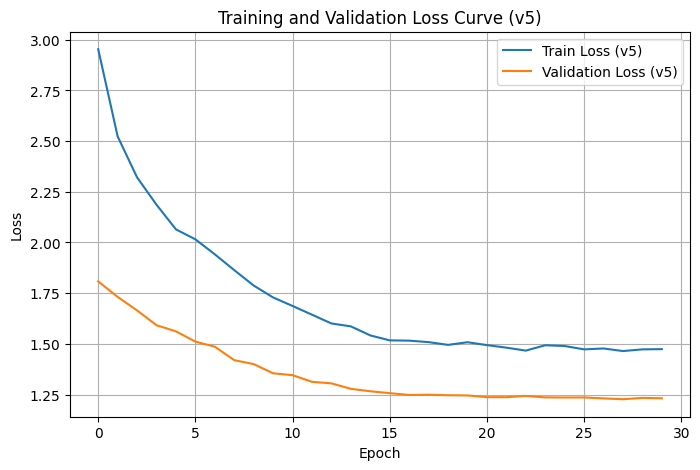

In [20]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(history_v5['train_loss'], label='Train Loss (v5)')
plt.plot(history_v5['val_loss'], label='Validation Loss (v5)')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss Curve (v5)')
plt.legend()
plt.grid(True)
plt.show()

In [16]:
# ---- Comparable AR BLEU-1/2/3/4 sweep (DeepSC-style sentence BLEU averaging) ----
import json
from pathlib import Path
import pandas as pd
from nltk.translate.bleu_score import sentence_bleu

BLEU_WEIGHTS = {
    "bleu1": (1.0, 0.0, 0.0, 0.0),
    "bleu2": (0.5, 0.5, 0.0, 0.0),
    "bleu3": (1/3, 1/3, 1/3, 0.0),
    "bleu4": (0.25, 0.25, 0.25, 0.25),
}

def decode_tokens_local(id_list):
    tokens = []
    for t in id_list:
        if t in (stoi[SOS], stoi[PAD]):
            continue
        if t == stoi[EOS]:
            break
        tokens.append(itos.get(int(t), UNK))
    return " ".join(tokens).strip()

def eval_ar_bleu_1234(model, loader, snr_db, max_batches=None):
    model.eval()
    out = {k: [] for k in BLEU_WEIGHTS.keys()}
    seen_batches = 0

    with torch.no_grad():
        for batch in loader:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            B = input_ids.size(0)

            for i in range(B):
                inp = input_ids[i:i+1]
                msk = attention_mask[i:i+1]

                ref_text = decode_tokens_local(input_ids[i].cpu().tolist())
                ref = ref_text.split()
                if not ref:
                    continue

                gen_ids = model.generate(inp, msk, snr_db=snr_db, sos_id=stoi[SOS], eos_id=stoi[EOS])
                hyp_text = decode_tokens_local(gen_ids.cpu().squeeze(0).tolist())
                hyp = hyp_text.split() if hyp_text.split() else ["the"]  # match DeepSC fallback

                for name, w in BLEU_WEIGHTS.items():
                    out[name].append(sentence_bleu([ref], hyp, weights=w))  # no smoothing (DeepSC-style)

            seen_batches += 1
            if max_batches is not None and seen_batches >= max_batches:
                break

    return {k: (sum(v) / len(v) if v else 0.0) for k, v in out.items()}


def ar_bleu1234_snr_sweep(model, loader, snr_values, max_batches=None):
    rows = []
    for snr in snr_values:
        scores = eval_ar_bleu_1234(model, loader, snr_db=snr, max_batches=max_batches)
        rows.append({"snr_db": snr, **scores})
        print(
            f"SNR {snr:>3} dB | "
            f"BLEU1={scores['bleu1']:.4f} "
            f"BLEU2={scores['bleu2']:.4f} "
            f"BLEU3={scores['bleu3']:.4f} "
            f"BLEU4={scores['bleu4']:.4f}"
        )
    return pd.DataFrame(rows)


def try_load_first_compatible_checkpoint(model):
    candidates = [
        ("semantic_best_v5.pt", "pt"),
        ("semantic_best.pt", "pt"),
        ("semantic_v5_checkpoint.pkl", "pkl"),
        ("semantic_checkpoint.pkl", "pkl"),
    ]
    for path_str, kind in candidates:
        ckpt_path = Path(path_str)
        if not ckpt_path.exists():
            continue
        try:
            if kind == "pt":
                state = torch.load(ckpt_path, map_location=device, weights_only=True)
            else:
                import pickle
                with ckpt_path.open("rb") as f:
                    payload = pickle.load(f)
                if "model_state" not in payload:
                    print(f"Skipping {ckpt_path}: missing model_state key")
                    continue
                state = payload["model_state"]
            model.load_state_dict(state)
            return ckpt_path
        except RuntimeError as e:
            print(f"Skipping incompatible checkpoint {ckpt_path}: {e}")
    return None


# ---- Run comparable evaluation ----
snr_values_match_deepsc = [0, 3, 6, 9, 12, 15, 18]   # match DeepSC config
eval_loader = loaders["test"]                         # match DeepSC eval_split=test
max_eval_batches = None                               # use full split for strict comparison

# Prefer v5 if architecture matches, fallback to v4/resume checkpoints.
ckpt = try_load_first_compatible_checkpoint(model)
if ckpt is None:
    print(
        "No compatible semantic checkpoint found. Train/save the aligned model first "
        "(e.g., semantic_best.pt or semantic_checkpoint.pkl)."
    )
else:
    ckpt_name = str(ckpt)
    model.to(device)
    model.eval()

    df_bleu1234 = ar_bleu1234_snr_sweep(
        model,
        eval_loader,
        snr_values_match_deepsc,
        max_batches=max_eval_batches
    )

    # Save CSV
    csv_out = Path("semantic_results_all_bleu_latest.csv")
    df_bleu1234.to_csv(csv_out, index=False)

    # Save JSON in DeepSC-like nested format
    payload = {
        "model": "semantic_v5",
        "checkpoint": ckpt_name,
        "snr_values": snr_values_match_deepsc,
        "bleu_by_snr": {
            str(int(row["snr_db"])): {
                "bleu1": float(row["bleu1"]),
                "bleu2": float(row["bleu2"]),
                "bleu3": float(row["bleu3"]),
                "bleu4": float(row["bleu4"]),
            }
            for _, row in df_bleu1234.iterrows()
        },
    }
    json_out = Path("semantic_results_all_bleu_latest.json")
    json_out.write_text(json.dumps(payload, indent=2), encoding="utf-8")

    print(f"Loaded checkpoint: {ckpt_name}")
    print(f"Saved: {csv_out}")
    print(f"Saved: {json_out}")

d:\btp_reso\btp_env\Lib\site-packages\nltk\translate\bleu_score.py:577: UserWarning: 
The hypothesis contains 0 counts of 3-gram overlaps.
Therefore the BLEU score evaluates to 0, independently of
how many N-gram overlaps of lower order it contains.
Consider using lower n-gram order or use SmoothingFunction()
  warnings.warn(_msg)
d:\btp_reso\btp_env\Lib\site-packages\nltk\translate\bleu_score.py:577: UserWarning: 
The hypothesis contains 0 counts of 4-gram overlaps.
Therefore the BLEU score evaluates to 0, independently of
how many N-gram overlaps of lower order it contains.
Consider using lower n-gram order or use SmoothingFunction()
  warnings.warn(_msg)
d:\btp_reso\btp_env\Lib\site-packages\nltk\translate\bleu_score.py:577: UserWarning: 
The hypothesis contains 0 counts of 2-gram overlaps.
Therefore the BLEU score evaluates to 0, independently of
how many N-gram overlaps of lower order it contains.
Consider using lower n-gram order or use SmoothingFunction()
  warnings.warn(_msg)


SNR   0 dB | BLEU1=0.4807 BLEU2=0.3394 BLEU3=0.2663 BLEU4=0.2245
SNR   3 dB | BLEU1=0.6626 BLEU2=0.5476 BLEU3=0.4668 BLEU4=0.4055
SNR   6 dB | BLEU1=0.8115 BLEU2=0.7361 BLEU3=0.6740 BLEU4=0.6136
SNR   9 dB | BLEU1=0.8840 BLEU2=0.8343 BLEU3=0.7899 BLEU4=0.7427
SNR  12 dB | BLEU1=0.9062 BLEU2=0.8650 BLEU3=0.8269 BLEU4=0.7852
SNR  15 dB | BLEU1=0.9139 BLEU2=0.8758 BLEU3=0.8402 BLEU4=0.8006
SNR  18 dB | BLEU1=0.9173 BLEU2=0.8804 BLEU3=0.8461 BLEU4=0.8077
Loaded checkpoint: semantic_best_v5.pt
Saved: semantic_results_all_bleu_latest.csv
Saved: semantic_results_all_bleu_latest.json


d:\btp_reso\btp_env\Lib\site-packages\nltk\translate\bleu_score.py:577: UserWarning: 
The hypothesis contains 0 counts of 4-gram overlaps.
Therefore the BLEU score evaluates to 0, independently of
how many N-gram overlaps of lower order it contains.
Consider using lower n-gram order or use SmoothingFunction()
  warnings.warn(_msg)
d:\btp_reso\btp_env\Lib\site-packages\nltk\translate\bleu_score.py:577: UserWarning: 
The hypothesis contains 0 counts of 3-gram overlaps.
Therefore the BLEU score evaluates to 0, independently of
how many N-gram overlaps of lower order it contains.
Consider using lower n-gram order or use SmoothingFunction()
  warnings.warn(_msg)
d:\btp_reso\btp_env\Lib\site-packages\nltk\translate\bleu_score.py:577: UserWarning: 
The hypothesis contains 0 counts of 2-gram overlaps.
Therefore the BLEU score evaluates to 0, independently of
how many N-gram overlaps of lower order it contains.
Consider using lower n-gram order or use SmoothingFunction()
  warnings.warn(_msg)


Collected 11816 per-sentence BLEU scores at SNR 6.0 dB


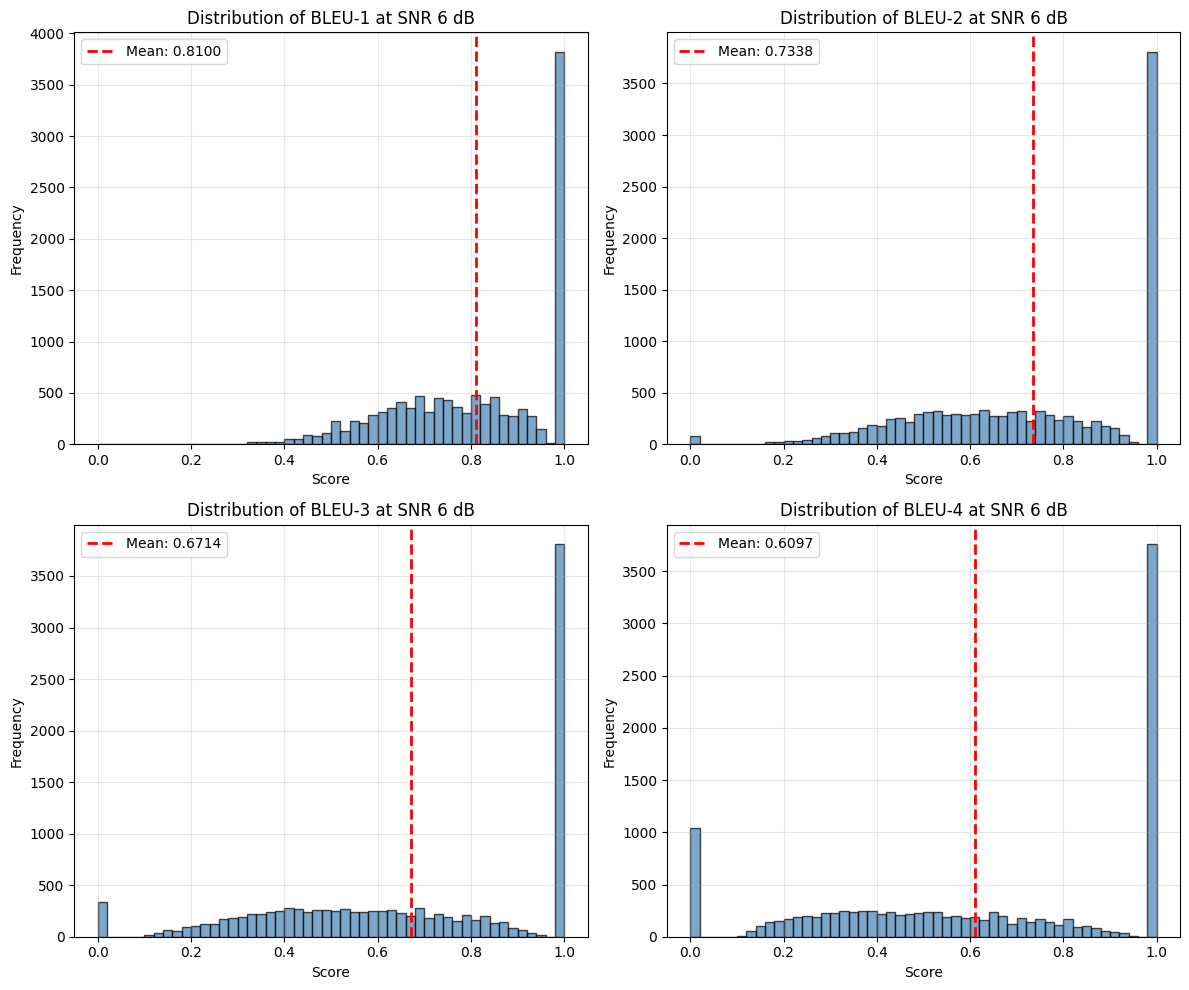


BLEU Score Statistics at SNR 6.0 dB (V5):
BLEU1 — Mean: 0.8100, Std: 0.1736, Min: 0.0000, Max: 1.0000
BLEU2 — Mean: 0.7338, Std: 0.2381, Min: 0.0000, Max: 1.0000
BLEU3 — Mean: 0.6714, Std: 0.2896, Min: 0.0000, Max: 1.0000
BLEU4 — Mean: 0.6097, Std: 0.3371, Min: 0.0000, Max: 1.0000

Saved: semantic_v5_bleu1234_distribution_snr6.png


In [21]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from nltk.translate.bleu_score import sentence_bleu

# ---- Distribution of BLEU-1/2/3/4 scores at SNR 6 dB for semantic v5 ----

ckpt_v5 = Path("semantic_best_v5.pt")
if not ckpt_v5.exists():
    raise FileNotFoundError(f"Missing checkpoint: {ckpt_v5}")

model.load_state_dict(torch.load(ckpt_v5, map_location=device, weights_only=True))
model.to(device)
model.eval()

snr_db = 6.0
max_batches = len(loaders["test"])

# Collect per-sentence BLEU scores (not averaged)
bleu1_scores = []
bleu2_scores = []
bleu3_scores = []
bleu4_scores = []

sos_id = stoi[SOS]
eos_id = stoi[EOS]
special_ids = {pad_id, stoi[SOS], stoi[EOS], stoi[UNK]}

def decode_tokens(id_list):
    toks = []
    for i in id_list:
        if i == stoi[EOS]:
            break
        if i in special_ids:
            continue
        toks.append(itos.get(i, UNK))
    return ' '.join(toks)

with torch.no_grad():
    for batch_idx, batch in enumerate(loaders["test"]):
        if batch_idx >= max_batches:
            break
        
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        bsz = input_ids.size(0)

        for i in range(bsz):
            inp = input_ids[i:i+1]
            msk = attention_mask[i:i+1]

            ref = decode_tokens(input_ids[i].cpu().tolist())
            ref_tokens = ref.split()
            if not ref_tokens:
                continue

            pred_ids = model.generate(inp, msk, snr_db=snr_db, sos_id=sos_id, eos_id=eos_id, max_len=max_len)
            hyp = decode_tokens(pred_ids.cpu().squeeze(0).tolist())
            hyp_tokens = hyp.split() if hyp.split() else ['the']

            bleu1_scores.append(sentence_bleu([ref_tokens], hyp_tokens, weights=(1, 0, 0, 0), smoothing_function=None))
            bleu2_scores.append(sentence_bleu([ref_tokens], hyp_tokens, weights=(0.5, 0.5, 0, 0), smoothing_function=None))
            bleu3_scores.append(sentence_bleu([ref_tokens], hyp_tokens, weights=(1/3, 1/3, 1/3, 0), smoothing_function=None))
            bleu4_scores.append(sentence_bleu([ref_tokens], hyp_tokens, weights=(0.25, 0.25, 0.25, 0.25), smoothing_function=None))

print(f"Collected {len(bleu1_scores)} per-sentence BLEU scores at SNR {snr_db} dB")

# Create 2x2 subplot histogram grid
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

all_scores = [bleu1_scores, bleu2_scores, bleu3_scores, bleu4_scores]
titles = ['Distribution of BLEU-1 at SNR 6 dB', 'Distribution of BLEU-2 at SNR 6 dB',
          'Distribution of BLEU-3 at SNR 6 dB', 'Distribution of BLEU-4 at SNR 6 dB']

for idx, (scores, title) in enumerate(zip(all_scores, titles)):
    mean_score = np.mean(scores)
    
    axes[idx].hist(scores, bins=50, color='steelblue', edgecolor='black', alpha=0.7)
    axes[idx].axvline(mean_score, color='red', linestyle='--', linewidth=2, 
                      label=f'Mean: {mean_score:.4f}')
    axes[idx].set_xlabel('Score')
    axes[idx].set_ylabel('Frequency')
    axes[idx].set_title(title)
    axes[idx].legend()
    axes[idx].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("semantic_v5_bleu1234_distribution_snr6.png", dpi=150, bbox_inches="tight")
plt.show()

# Print summary statistics
print(f"\nBLEU Score Statistics at SNR {snr_db} dB (V5):")
print(f"BLEU1 — Mean: {np.mean(bleu1_scores):.4f}, Std: {np.std(bleu1_scores):.4f}, Min: {np.min(bleu1_scores):.4f}, Max: {np.max(bleu1_scores):.4f}")
print(f"BLEU2 — Mean: {np.mean(bleu2_scores):.4f}, Std: {np.std(bleu2_scores):.4f}, Min: {np.min(bleu2_scores):.4f}, Max: {np.max(bleu2_scores):.4f}")
print(f"BLEU3 — Mean: {np.mean(bleu3_scores):.4f}, Std: {np.std(bleu3_scores):.4f}, Min: {np.min(bleu3_scores):.4f}, Max: {np.max(bleu3_scores):.4f}")
print(f"BLEU4 — Mean: {np.mean(bleu4_scores):.4f}, Std: {np.std(bleu4_scores):.4f}, Min: {np.min(bleu4_scores):.4f}, Max: {np.max(bleu4_scores):.4f}")
print(f"\nSaved: semantic_v5_bleu1234_distribution_snr6.png")

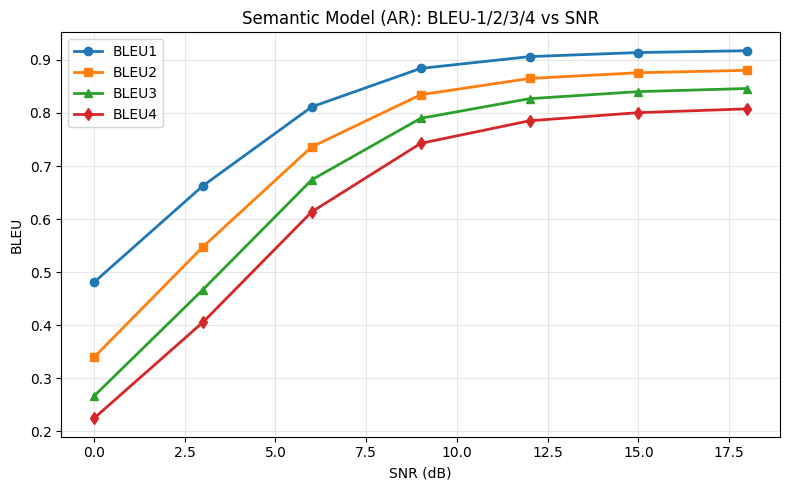

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

csv_path = Path("semantic_results_all_bleu_latest.csv")
if not csv_path.exists():
    print(f"Missing file: {csv_path}. Run BLEU sweep cell first.")
else:
    df = pd.read_csv(csv_path)

    plt.figure(figsize=(8, 5))
    for col, marker in [("bleu1", "o"), ("bleu2", "s"), ("bleu3", "^"), ("bleu4", "d")]:
        if col in df.columns:
            plt.plot(df["snr_db"], df[col], marker=marker, linewidth=2, label=col.upper())

    plt.xlabel("SNR (dB)")
    plt.ylabel("BLEU")
    plt.title("Semantic Model (AR): BLEU-1/2/3/4 vs SNR")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.savefig("semantic_bleu1234_snr.png", dpi=150, bbox_inches="tight")
    plt.show()

In [22]:
import random
import torch
import pandas as pd
from pathlib import Path
from nltk.translate.bleu_score import sentence_bleu

# -------------------- Config --------------------
snr_values = [0, 3, 6, 9, 12, 15, 18]
reference_snr = 6.0
bleu4_min, bleu4_max = 0.6, 0.9
num_samples = 8          # "few samples"
candidate_pool_size = 80  # stop early once enough candidates are found
seed = 42
random.seed(seed)

# -------------------- Helpers --------------------
def decode_tokens_local(id_list):
    tokens = []
    for t in id_list:
        if t in (stoi[SOS], stoi[PAD]):
            continue
        if t == stoi[EOS]:
            break
        tokens.append(itos.get(int(t), UNK))
    return " ".join(tokens).strip()

def bleu_scores(ref_tokens, hyp_tokens):
    return {
        "bleu1": sentence_bleu([ref_tokens], hyp_tokens, weights=(1, 0, 0, 0), smoothing_function=None),
        "bleu2": sentence_bleu([ref_tokens], hyp_tokens, weights=(0.5, 0.5, 0, 0), smoothing_function=None),
        "bleu3": sentence_bleu([ref_tokens], hyp_tokens, weights=(1/3, 1/3, 1/3, 0), smoothing_function=None),
        "bleu4": sentence_bleu([ref_tokens], hyp_tokens, weights=(0.25, 0.25, 0.25, 0.25), smoothing_function=None),
    }

# -------------------- Load v5 checkpoint --------------------
ckpt_v5 = Path("semantic_best_v5.pt")
if not ckpt_v5.exists():
    raise FileNotFoundError(f"Missing checkpoint: {ckpt_v5}")

model.load_state_dict(torch.load(ckpt_v5, map_location=device, weights_only=True))
model.to(device)
model.eval()

sos_id = stoi[SOS]
eos_id = stoi[EOS]

# -------------------- Step 1: collect candidate samples at reference SNR --------------------
print(f"Scanning test set for BLEU-4 in [{bleu4_min}, {bleu4_max}] at {reference_snr} dB...")
candidates = []
global_idx = 0

with torch.no_grad():
    for batch in loaders["test"]:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        bsz = input_ids.size(0)

        for i in range(bsz):
            inp = input_ids[i:i+1]
            msk = attention_mask[i:i+1]

            ref = decode_tokens_local(input_ids[i].cpu().tolist())
            ref_tokens = ref.split()
            if not ref_tokens:
                global_idx += 1
                continue

            pred_ids = model.generate(inp, msk, snr_db=reference_snr, sos_id=sos_id, eos_id=eos_id, max_len=max_len)
            hyp = decode_tokens_local(pred_ids.cpu().squeeze(0).tolist())
            hyp_tokens = hyp.split() if hyp.split() else ["the"]

            b4 = sentence_bleu([ref_tokens], hyp_tokens, weights=(0.25, 0.25, 0.25, 0.25), smoothing_function=None)

            if bleu4_min <= b4 <= bleu4_max:
                candidates.append({
                    "sample_idx": global_idx,
                    "input_ids": input_ids[i:i+1].detach().cpu(),
                    "attention_mask": attention_mask[i:i+1].detach().cpu(),
                    "reference": ref,
                    "bleu4_at_6db": b4,
                })
                if len(candidates) >= candidate_pool_size:
                    break

            global_idx += 1

        if len(candidates) >= candidate_pool_size:
            break

print(f"Found {len(candidates)} candidates.")

if len(candidates) == 0:
    print("No samples found in the requested BLEU-4 range. Try widening the range (e.g., 0.5 to 0.9).")
else:
    # -------------------- Step 2: pick few random samples --------------------
    k = min(num_samples, len(candidates))
    selected = random.sample(candidates, k)
    print(f"Randomly selected {k} samples.")

    # -------------------- Step 3: reconstruct across all SNRs --------------------
    rows = []
    with torch.no_grad():
        for s_idx, sample in enumerate(selected, start=1):
            ref = sample["reference"]
            ref_tokens = ref.split()
            inp = sample["input_ids"].to(device)
            msk = sample["attention_mask"].to(device)

            print("\n" + "=" * 120)
            print(f"Sample {s_idx}/{k} | test_idx={sample['sample_idx']} | BLEU4@6dB(ref-filter)={sample['bleu4_at_6db']:.4f}")
            print(f"Reference: {ref}")

            for snr in snr_values:
                pred_ids = model.generate(inp, msk, snr_db=snr, sos_id=sos_id, eos_id=eos_id, max_len=max_len)
                hyp = decode_tokens_local(pred_ids.cpu().squeeze(0).tolist())
                hyp_tokens = hyp.split() if hyp.split() else ["the"]

                b = bleu_scores(ref_tokens, hyp_tokens)

                print(f"SNR {snr:>2} dB: {hyp}")
                print(f"          BLEU1={b['bleu1']:.4f} | BLEU2={b['bleu2']:.4f} | BLEU3={b['bleu3']:.4f} | BLEU4={b['bleu4']:.4f}")

                rows.append({
                    "picked_sample_no": s_idx,
                    "sample_idx": sample["sample_idx"],
                    "reference": ref,
                    "reference_bleu4_at_6db": round(sample["bleu4_at_6db"], 4),
                    "snr_db": snr,
                    "hypothesis": hyp,
                    "bleu1": b["bleu1"],
                    "bleu2": b["bleu2"],
                    "bleu3": b["bleu3"],
                    "bleu4": b["bleu4"],
                })

    # -------------------- Save --------------------
    df_out = pd.DataFrame(rows)
    out_csv = Path("semantic_v5_reconstructions_bleu4_0.6_to_0.9.csv")
    df_out.to_csv(out_csv, index=False)

    print("\nSaved:", out_csv)
    display(df_out.head(20))

Scanning test set for BLEU-4 in [0.6, 0.9] at 6.0 dB...


d:\btp_reso\btp_env\Lib\site-packages\nltk\translate\bleu_score.py:577: UserWarning: 
The hypothesis contains 0 counts of 4-gram overlaps.
Therefore the BLEU score evaluates to 0, independently of
how many N-gram overlaps of lower order it contains.
Consider using lower n-gram order or use SmoothingFunction()
  warnings.warn(_msg)
d:\btp_reso\btp_env\Lib\site-packages\nltk\translate\bleu_score.py:577: UserWarning: 
The hypothesis contains 0 counts of 3-gram overlaps.
Therefore the BLEU score evaluates to 0, independently of
how many N-gram overlaps of lower order it contains.
Consider using lower n-gram order or use SmoothingFunction()
  warnings.warn(_msg)
d:\btp_reso\btp_env\Lib\site-packages\nltk\translate\bleu_score.py:577: UserWarning: 
The hypothesis contains 0 counts of 2-gram overlaps.
Therefore the BLEU score evaluates to 0, independently of
how many N-gram overlaps of lower order it contains.
Consider using lower n-gram order or use SmoothingFunction()
  warnings.warn(_msg)


Found 80 candidates.
Randomly selected 8 samples.

Sample 1/8 | test_idx=88 | BLEU4@6dB(ref-filter)=0.8916
Reference: the sixth and final point calling on china to comply with international rules protecting workers and human rights
SNR  0 dB: the context the commission had provided for active confidence to combat humanitarian humanitarian service and workers commissioner including including commissioner please meet issues in drugs and production and and
          BLEU1=0.1724 | BLEU2=0.0000 | BLEU3=0.0000 | BLEU4=0.0000
SNR  3 dB: the outcome the fourth concern directly to achieve to to motor trade rules working workers and human rights
          BLEU1=0.3889 | BLEU2=0.2620 | BLEU3=0.2047 | BLEU4=0.1546
SNR  6 dB: the fifth and legal points calling on china to comply with international rules protecting workers and human rights
          BLEU1=0.8333 | BLEU2=0.7670 | BLEU3=0.7395 | BLEU4=0.7206
SNR  9 dB: the czech and final point calling on china to comply with international rules prot

,picked_sample_no,sample_idx,reference,reference_bleu4_at_6db,snr_db,hypothesis,bleu1,bleu2,bleu3,bleu4
0,1,88,the sixth and final point calling on china to ...,0.8916,0,the context the commission had provided for ac...,0.172414,6.193815e-155,4.403050e-206,1.173955e-231
1,1,88,the sixth and final point calling on china to ...,0.8916,3,the outcome the fourth concern directly to ach...,0.388889,2.619684e-01,2.047085e-01,1.546426e-01
2,1,88,the sixth and final point calling on china to ...,0.8916,6,the fifth and legal points calling on china to...,0.833333,7.669650e-01,7.395052e-01,7.205815e-01
3,1,88,the sixth and final point calling on china to ...,0.8916,9,the czech and final point calling on china to ...,0.944444,9.128709e-01,9.000686e-01,8.915993e-01
4,1,88,the sixth and final point calling on china to ...,0.8916,12,the eib and final point calling on china to co...,0.944444,9.128709e-01,9.000686e-01,8.915993e-01
5,1,88,the sixth and final point calling on china to ...,0.8916,15,the fifth and final point calling on china to ...,0.944444,9.128709e-01,9.000686e-01,8.915993e-01
6,1,88,the sixth and final point calling on china to ...,0.8916,18,the fifth and final point calling on china to ...,0.944444,9.128709e-01,9.000686e-01,8.915993e-01
7,2,11,question no 12 by h 0611 01,0.6435,0,question no 12 by h 9 01,0.857143,7.559289e-01,6.999028e-01,6.434589e-01
8,2,11,question no 12 by h 0611 01,0.6435,3,question no 12 by h h 01,0.857143,7.559289e-01,6.999028e-01,6.434589e-01
9,2,11,question no 12 by h 0611 01,0.6435,6,question no 12 by h 12 01,0.857143,7.559289e-01,6.999028e-01,6.434589e-01
